# V17 ΔMIC benchmark reproduction / V17 基准复算

This notebook uses only packaged predictions and timing records. It reconstructs all four family-macro metrics for 23 backbones, two training conditions and ten seeds. The original V17 manuscript PDFs are preserved in `figures/reference/`. Each figure has its own editable cell. No models are trained and no checkpoints are loaded.

本 Notebook 仅使用包内归档预测与计时记录，复算 23 个骨干、两个训练方案、十个种子的四指标。每图单独一个代码块。原始论文图见 `figures/reference/`，不会被覆盖。

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
candidate = Path.cwd().resolve()
ROOT = next(p for p in [candidate, *candidate.parents] if (p / 'code/evaluate.py').is_file() and (p / 'data/canonical_pairs.csv').is_file())
sys.path.insert(0, str(ROOT / 'code'))
import evaluate
import plot_results as plots
OUT = ROOT / 'reproduced'
validation = evaluate.run(OUT, check_reference=True)

from IPython.display import display, Image
import io
def show(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=130)
    display(Image(data=buffer.getvalue()))


{
  "status": "PASS",
  "methods": 23,
  "conditions": 2,
  "seeds": [
    120,
    121,
    122,
    123,
    124,
    125,
    126,
    127,
    128,
    129
  ],
  "peptides": 208,
  "families": 11,
  "pairs": 2211,
  "prediction_sets": 460,
  "peptide_to_pair_checks": 420,
  "family_metric_rows": 5060,
  "numeric_reference_checks": 23660,
  "ensemble_seeds": 10,
  "timing_methods_verified": 23,
  "undefined_correlations": [
    {
      "method": "AMPLiT",
      "condition": "with_negatives",
      "seed": 122,
      "family": "Hydrodamin-3"
    }
  ]
}


## Endpoint and summary / 终点与汇总

The 2,211 oriented pairs are evaluated within 11 families. Each family has equal weight. Seed summaries are then averaged over seeds 120–129; SD is the sample SD. Undefined correlations propagate. For an absolute predictor, log10 MIC is harmonized to µg/mL before differencing and conversion to log2 units.

2,211 个配对先按 11 个家族分别计算指标，再等权平均；最后汇总十种子的均值与样本标准差。未定义相关系数向上层汇总传播。绝对活性预测先统一为 µg/mL 的 log10 MIC，再构建 log2 配对差值。

In [2]:
summary = pd.read_csv(OUT / 'benchmark_summary.csv')
selected = pd.read_csv(OUT / 'pcc_selected.csv')
display(selected[['method', 'condition', 'PCC', 'KCC', 'log10MAE', 'RSE']])


,method,condition,PCC,KCC,log10MAE,RSE
0,TIGER-pair,with_negatives,0.654320,0.472940,0.381269,0.665917
1,TIGER-single,with_negatives,0.627326,0.450965,0.402097,0.752231
2,AMPActiPred,with_negatives,0.603769,0.450589,0.372685,0.659454
3,HyperAMP,without_negatives,0.542639,0.394177,0.409583,0.746298
4,APEX,with_negatives,0.516610,0.364625,0.425054,0.883201
5,LLAMP,with_negatives,0.510927,0.373979,0.416350,0.854577
6,Das,with_negatives,0.493412,0.367790,0.437335,1.105558
7,AMPlify,with_negatives,0.489086,0.360285,0.428852,0.965608
8,EvoGradient,with_negatives,0.483458,0.362856,0.415564,0.819494
9,BERT-AmPEP60,with_negatives,0.481471,0.337102,0.468353,1.275356


## Family-macro PCC

With-negative training for every backbone. Points show the ten-seed mean and bars the 95% Student t interval. AMPLiT constant-family correlations remain NA. 

所有骨干统一采用含负样本方案；点为十种子均值，线为 95% t 置信区间。AMPLiT 的恒定预测相关系数保留为 NA。

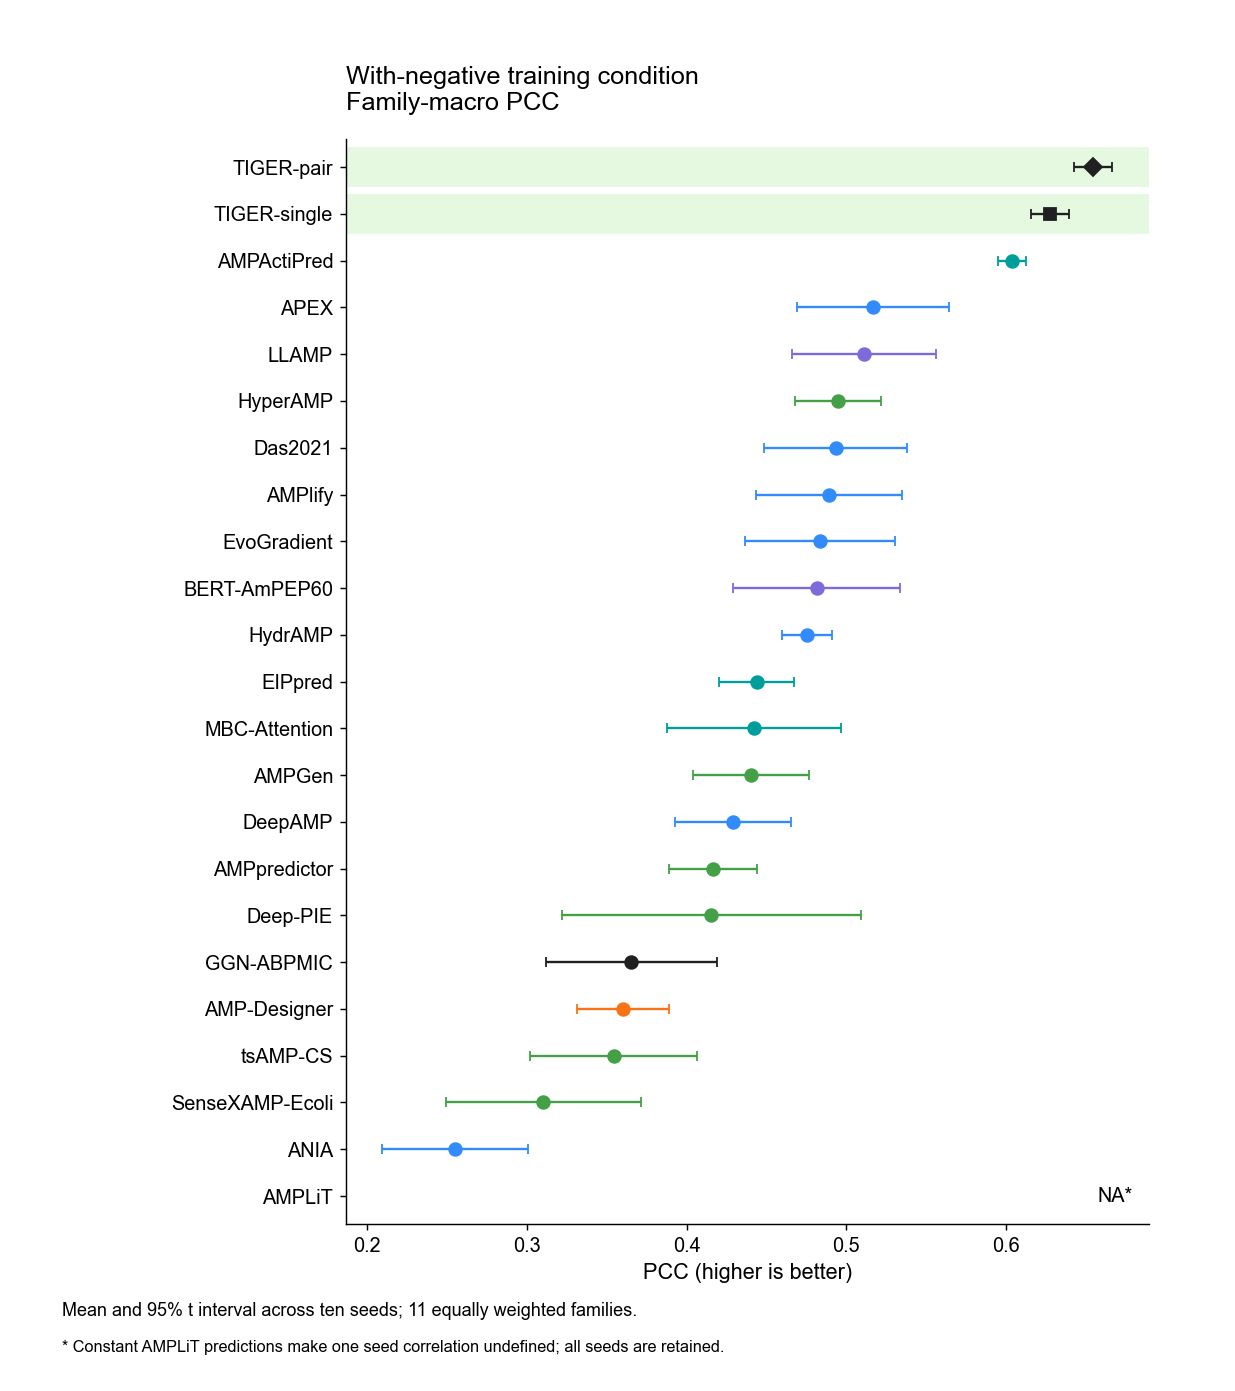

In [3]:
fig = plots.benchmark(OUT, metric='PCC', ensemble=False)
# Customize fig size / fonts here, then export to a new filename.
plots.export(fig, OUT / 'figures' / 'benchmark_PCC')
show(fig)
plt.close(fig)


## Family-macro KCC

With-negative training for every backbone. Points show the ten-seed mean and bars the 95% Student t interval. AMPLiT constant-family correlations remain NA. 

所有骨干统一采用含负样本方案；点为十种子均值，线为 95% t 置信区间。AMPLiT 的恒定预测相关系数保留为 NA。

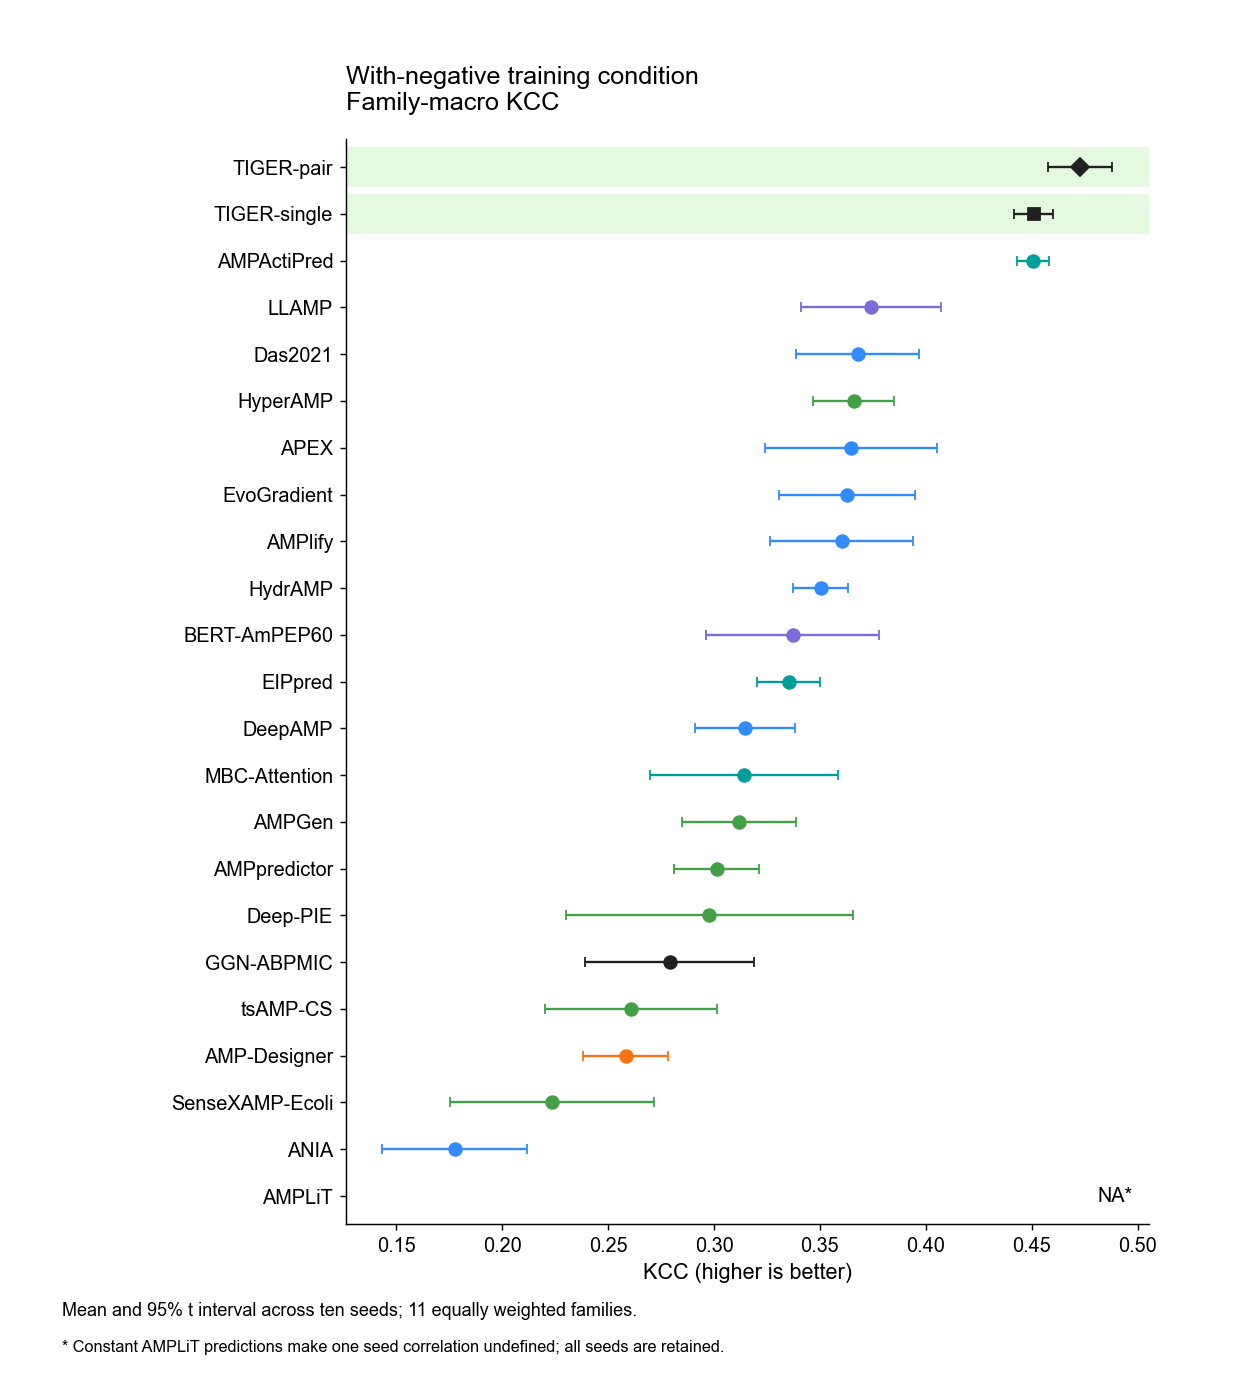

In [4]:
fig = plots.benchmark(OUT, metric='KCC', ensemble=False)
# Customize fig size / fonts here, then export to a new filename.
plots.export(fig, OUT / 'figures' / 'benchmark_KCC')
show(fig)
plt.close(fig)


## Family-macro log10MAE

With-negative training for every backbone. Points show the ten-seed mean and bars the 95% Student t interval. AMPLiT constant-family correlations remain NA. 

所有骨干统一采用含负样本方案；点为十种子均值，线为 95% t 置信区间。AMPLiT 的恒定预测相关系数保留为 NA。

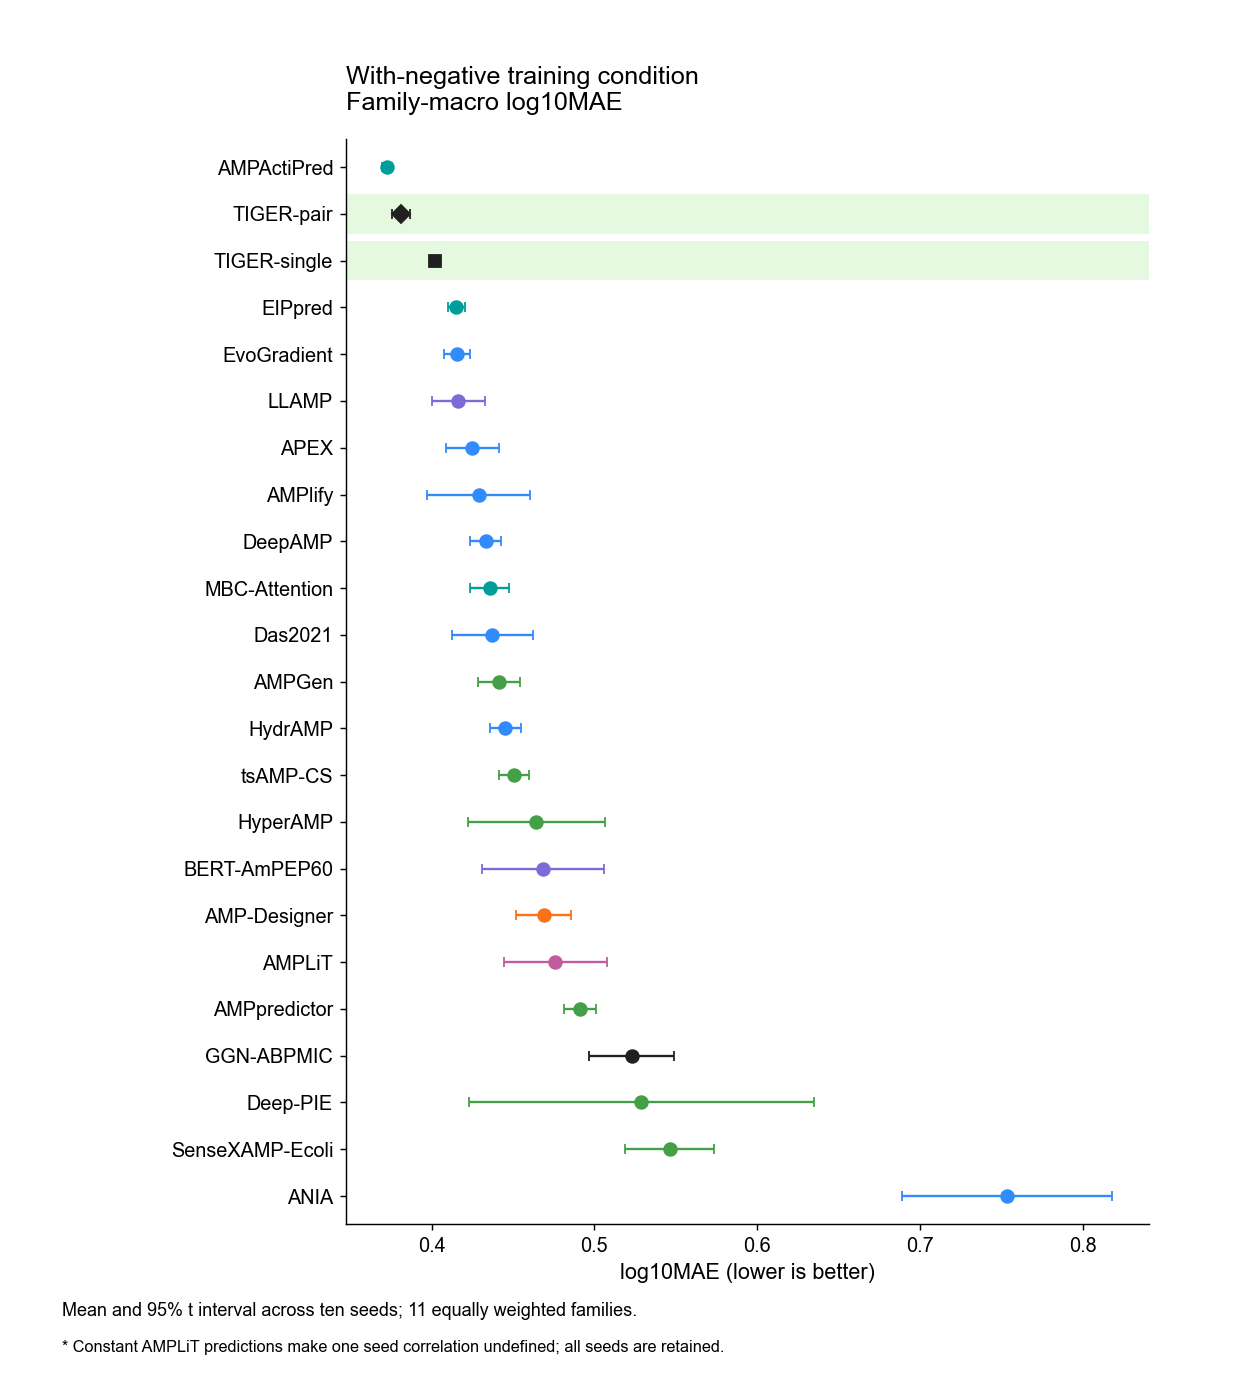

In [5]:
fig = plots.benchmark(OUT, metric='log10MAE', ensemble=False)
# Customize fig size / fonts here, then export to a new filename.
plots.export(fig, OUT / 'figures' / 'benchmark_log10MAE')
show(fig)
plt.close(fig)


## Family-macro RSE

With-negative training for every backbone. Points show the ten-seed mean and bars the 95% Student t interval. AMPLiT constant-family correlations remain NA. 

所有骨干统一采用含负样本方案；点为十种子均值，线为 95% t 置信区间。AMPLiT 的恒定预测相关系数保留为 NA。

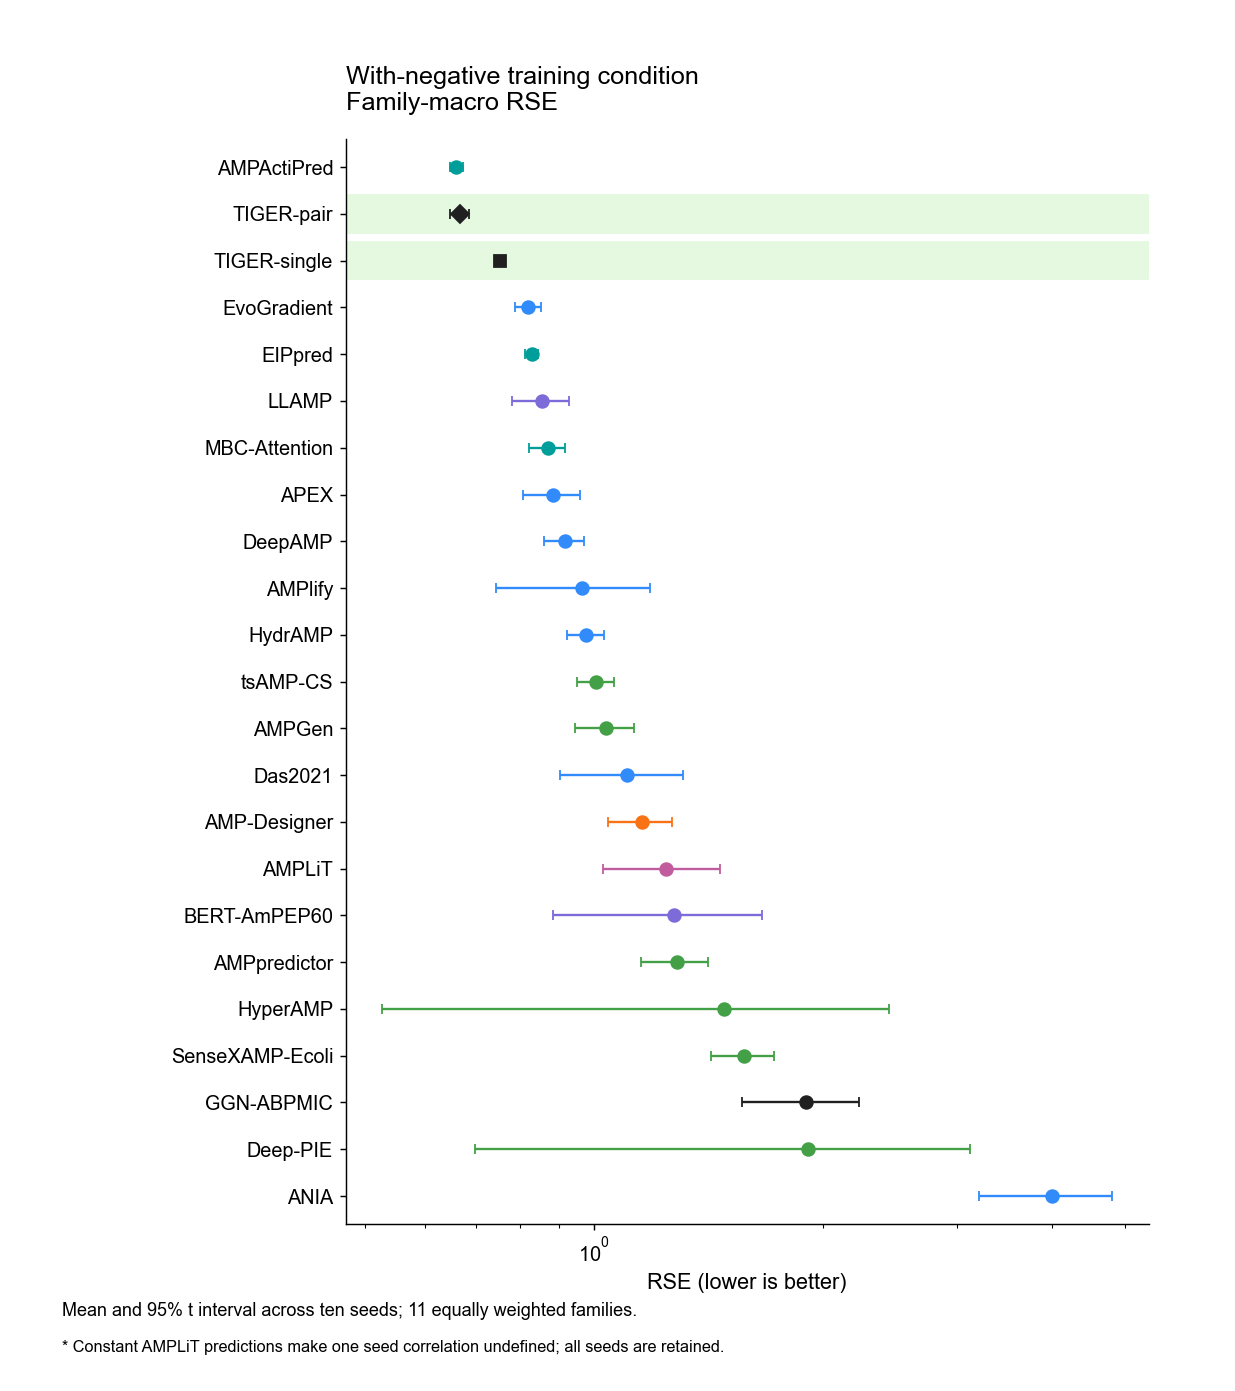

In [6]:
fig = plots.benchmark(OUT, metric='RSE', ensemble=False)
# Customize fig size / fonts here, then export to a new filename.
plots.export(fig, OUT / 'figures' / 'benchmark_RSE')
show(fig)
plt.close(fig)


## Family-macro PCC with TIGER-ensemble

With-negative training for every backbone. Points show the ten-seed mean and bars the 95% Student t interval. AMPLiT constant-family correlations remain NA. The ensemble averages same-seed calibrated TIGER-pair and TIGER-single predictions with equal weights.

所有骨干统一采用含负样本方案；点为十种子均值，线为 95% t 置信区间。AMPLiT 的恒定预测相关系数保留为 NA。集成为同种子两模型校准预测的等权平均。

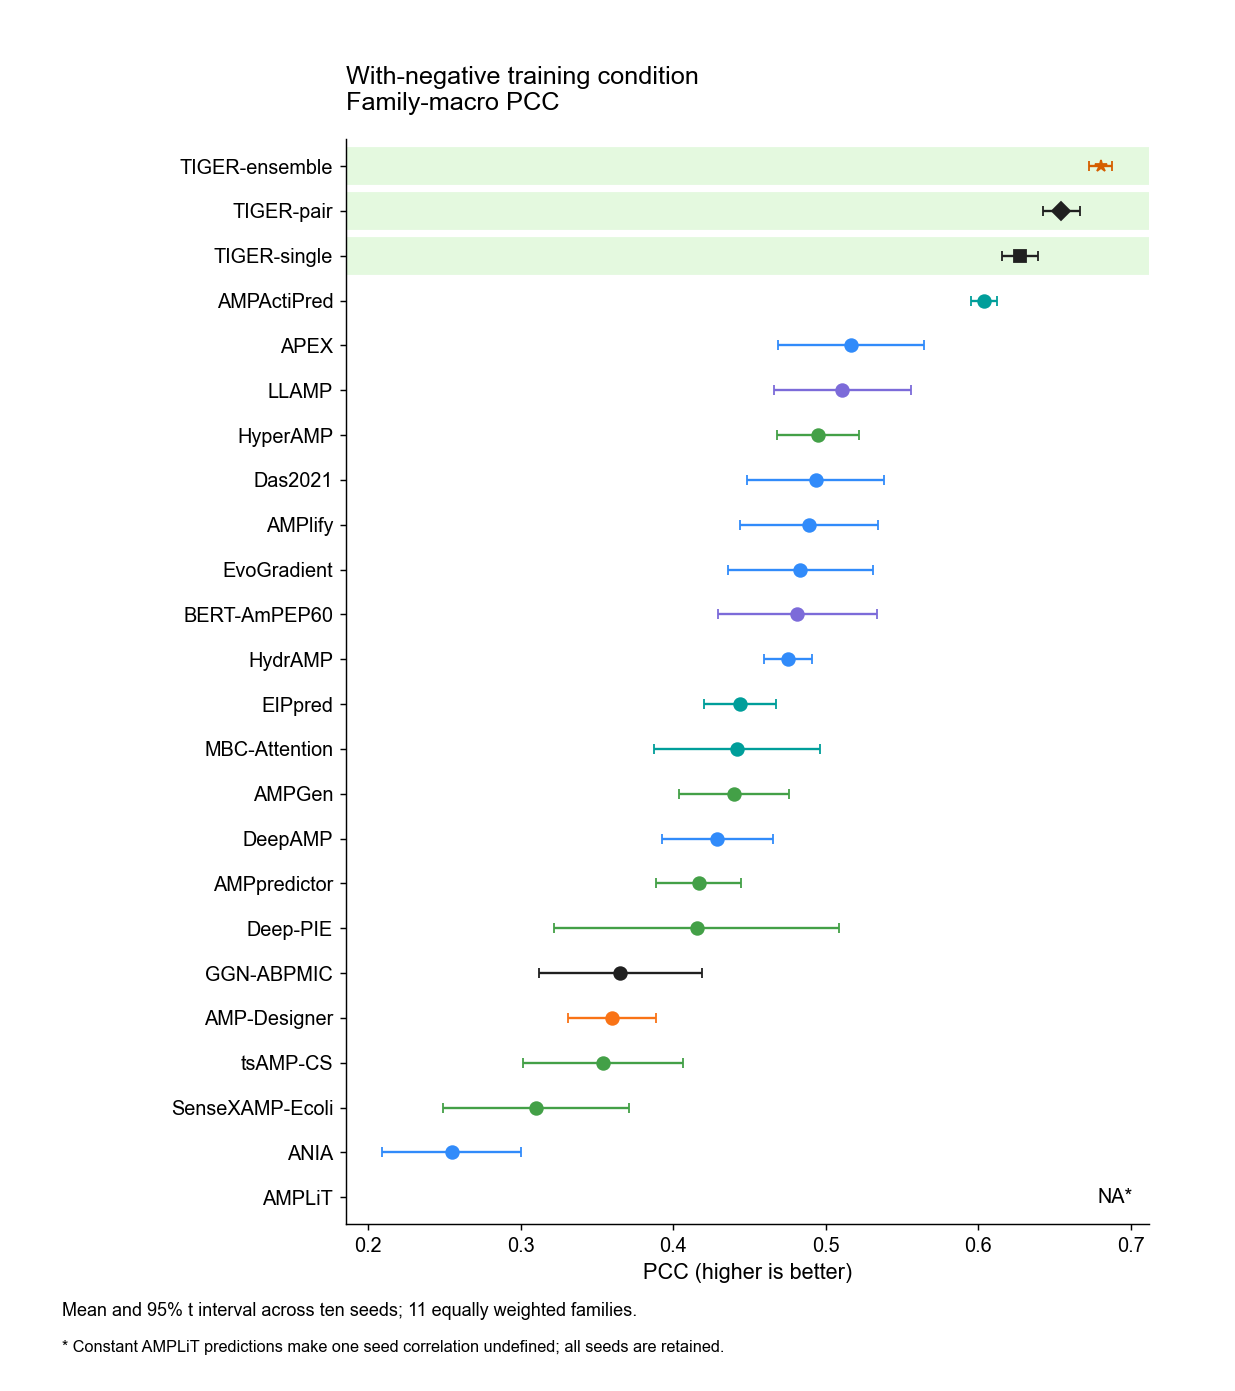

In [7]:
fig = plots.benchmark(OUT, metric='PCC', ensemble=True)
# Customize fig size / fonts here, then export to a new filename.
plots.export(fig, OUT / 'figures' / 'benchmark_ensemble_PCC')
show(fig)
plt.close(fig)


## Family-macro KCC with TIGER-ensemble

With-negative training for every backbone. Points show the ten-seed mean and bars the 95% Student t interval. AMPLiT constant-family correlations remain NA. The ensemble averages same-seed calibrated TIGER-pair and TIGER-single predictions with equal weights.

所有骨干统一采用含负样本方案；点为十种子均值，线为 95% t 置信区间。AMPLiT 的恒定预测相关系数保留为 NA。集成为同种子两模型校准预测的等权平均。

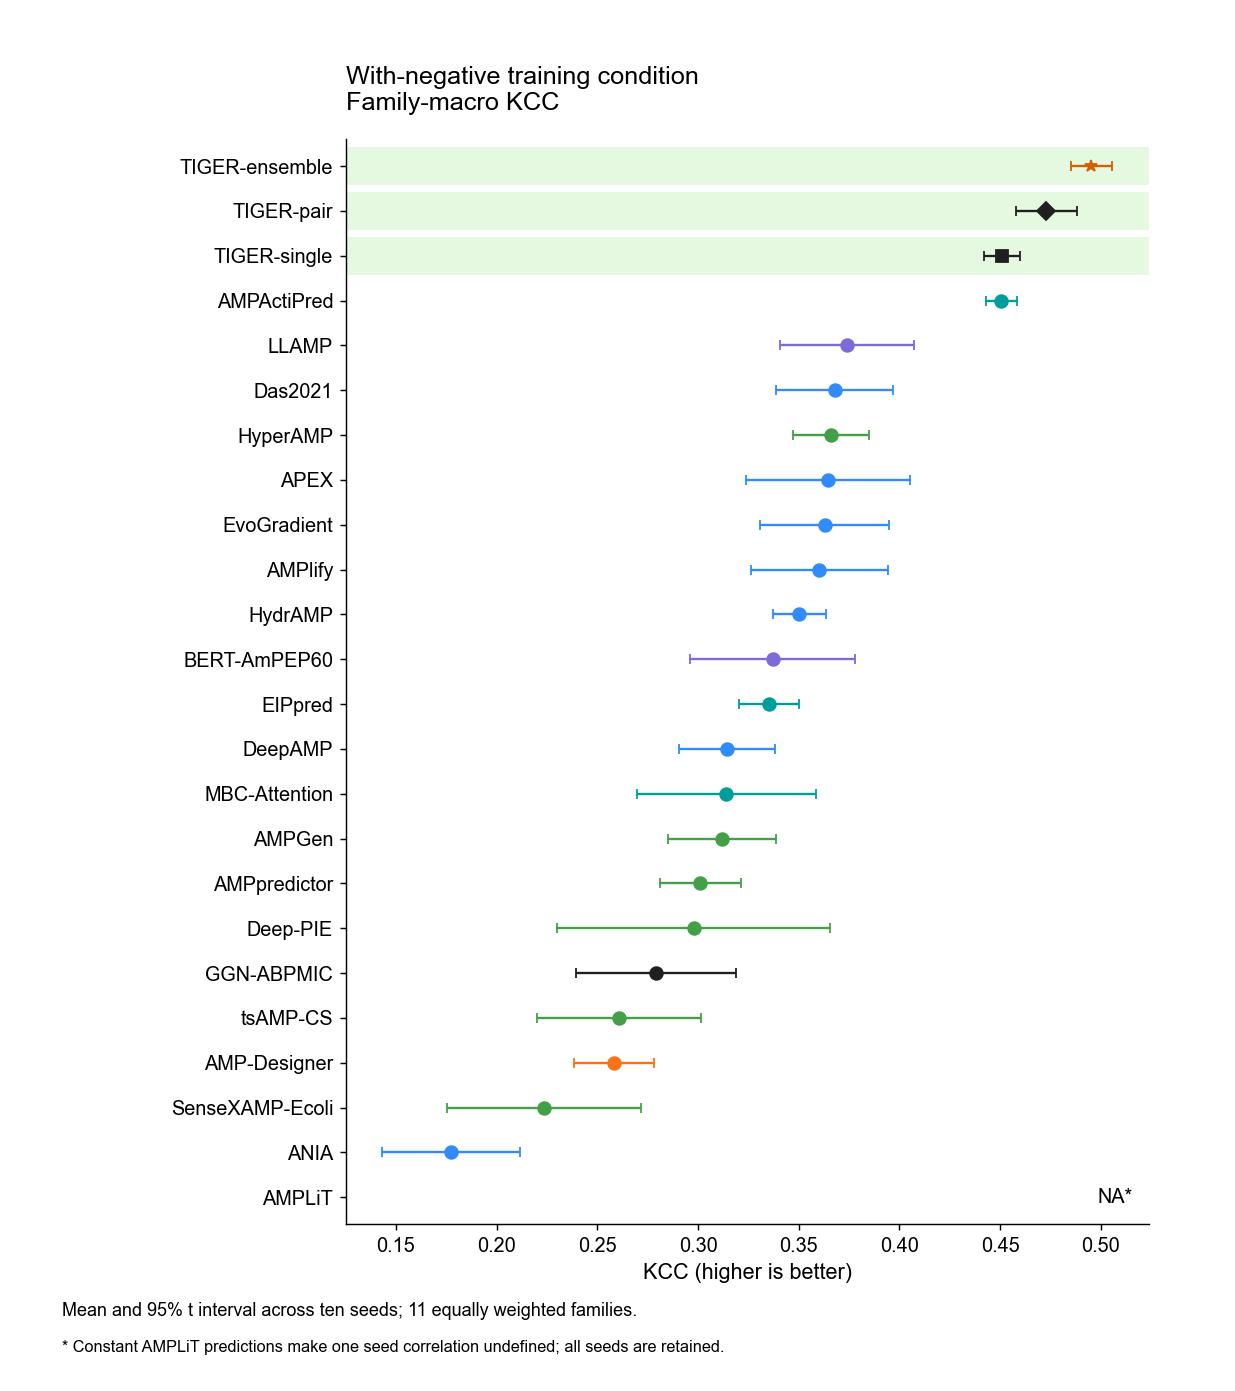

In [8]:
fig = plots.benchmark(OUT, metric='KCC', ensemble=True)
# Customize fig size / fonts here, then export to a new filename.
plots.export(fig, OUT / 'figures' / 'benchmark_ensemble_KCC')
show(fig)
plt.close(fig)


## Family-macro log10MAE with TIGER-ensemble

With-negative training for every backbone. Points show the ten-seed mean and bars the 95% Student t interval. AMPLiT constant-family correlations remain NA. The ensemble averages same-seed calibrated TIGER-pair and TIGER-single predictions with equal weights.

所有骨干统一采用含负样本方案；点为十种子均值，线为 95% t 置信区间。AMPLiT 的恒定预测相关系数保留为 NA。集成为同种子两模型校准预测的等权平均。

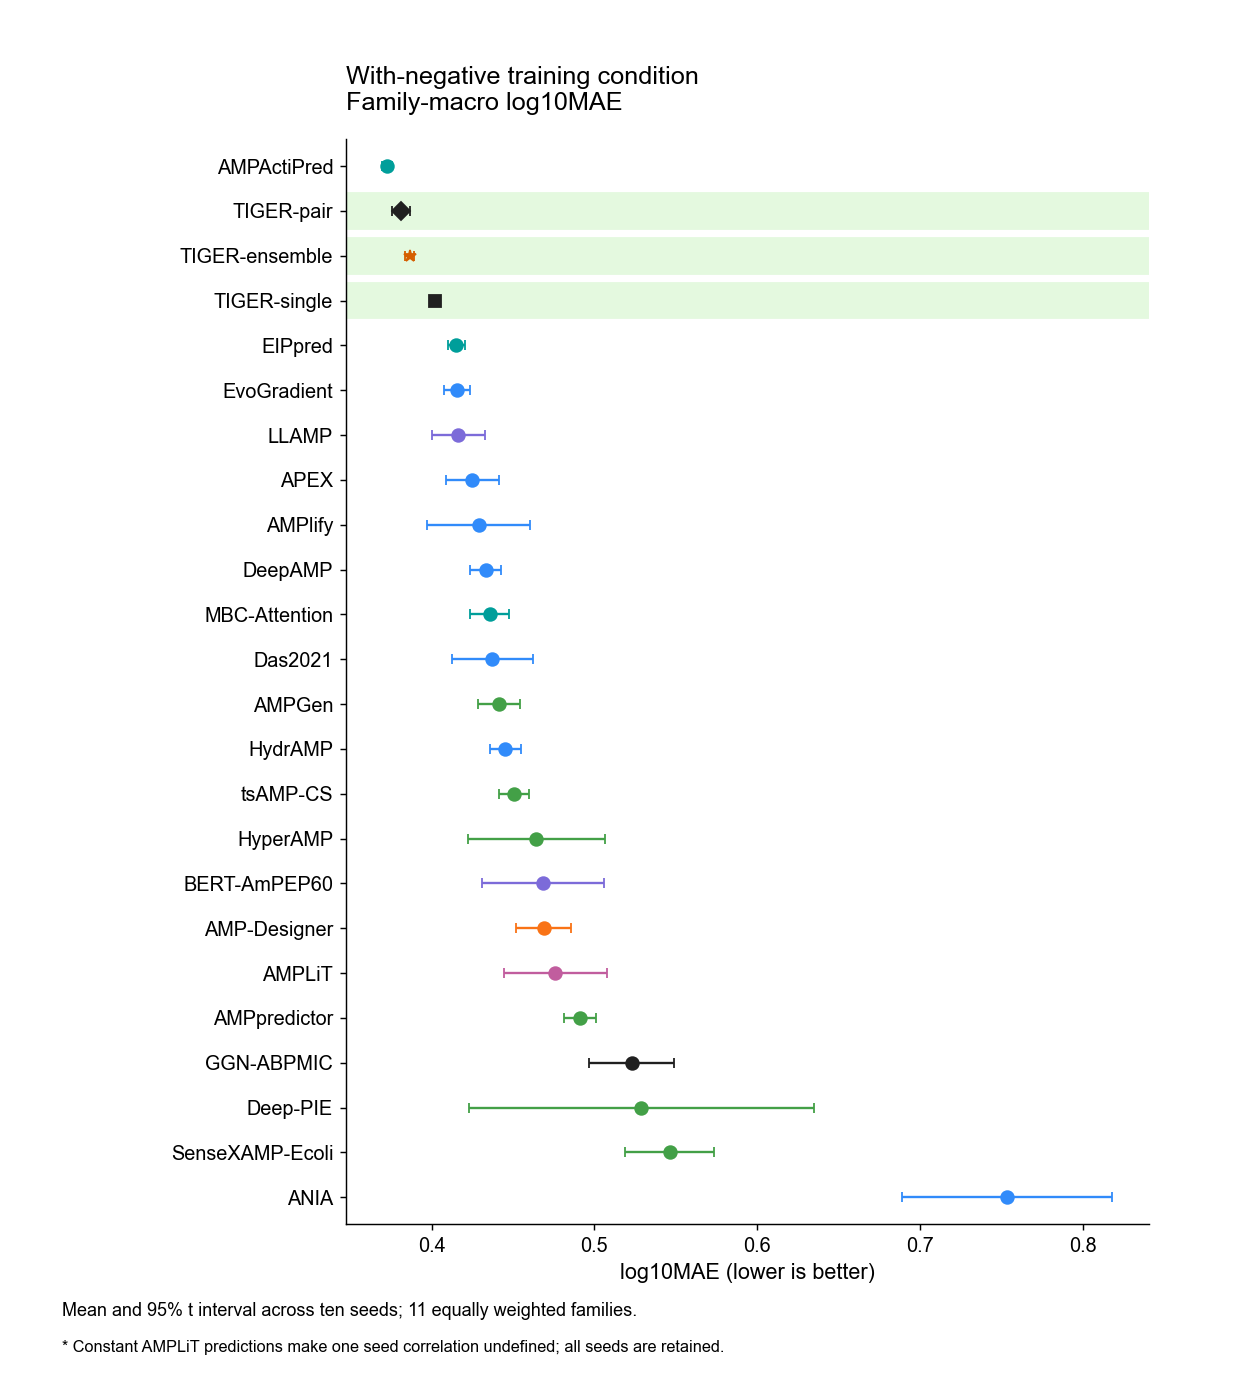

In [9]:
fig = plots.benchmark(OUT, metric='log10MAE', ensemble=True)
# Customize fig size / fonts here, then export to a new filename.
plots.export(fig, OUT / 'figures' / 'benchmark_ensemble_log10MAE')
show(fig)
plt.close(fig)


## Family-macro RSE with TIGER-ensemble

With-negative training for every backbone. Points show the ten-seed mean and bars the 95% Student t interval. AMPLiT constant-family correlations remain NA. The ensemble averages same-seed calibrated TIGER-pair and TIGER-single predictions with equal weights.

所有骨干统一采用含负样本方案；点为十种子均值，线为 95% t 置信区间。AMPLiT 的恒定预测相关系数保留为 NA。集成为同种子两模型校准预测的等权平均。

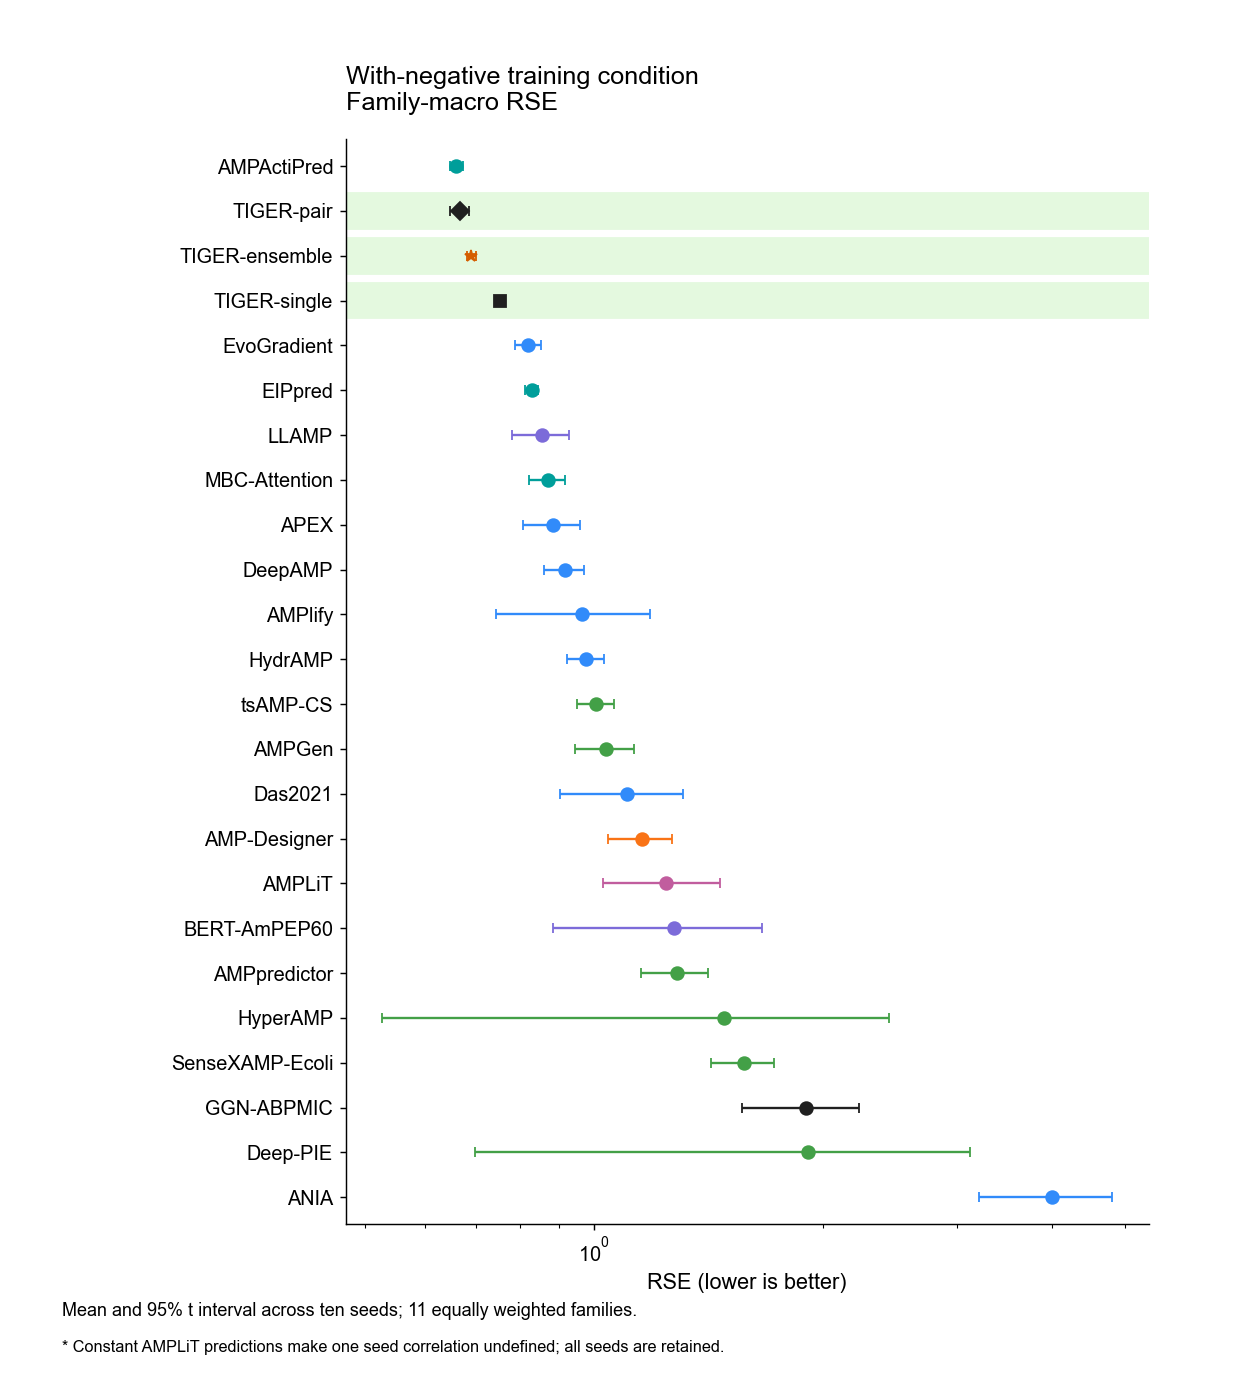

In [10]:
fig = plots.benchmark(OUT, metric='RSE', ensemble=True)
# Customize fig size / fonts here, then export to a new filename.
plots.export(fig, OUT / 'figures' / 'benchmark_ensemble_RSE')
show(fig)
plt.close(fig)


## Accuracy and cost — PCC, main

One complete condition per backbone, selected by PCC.  Timings use the with-negative seed-123 workload for both conditions. Structure generation adds a serial estimate of 328.12 s to structural pipelines. Dashed structural connectors and frontier segments are visual guides. Hollow points indicate structures already available.

每个骨干按 PCC 选择一个完整方案，PCC 与 RSE 使用相同方案。空心点表示结构已备。两条件共用含负样本方案的计时；结构生成增加 328.12 s 串行估计。

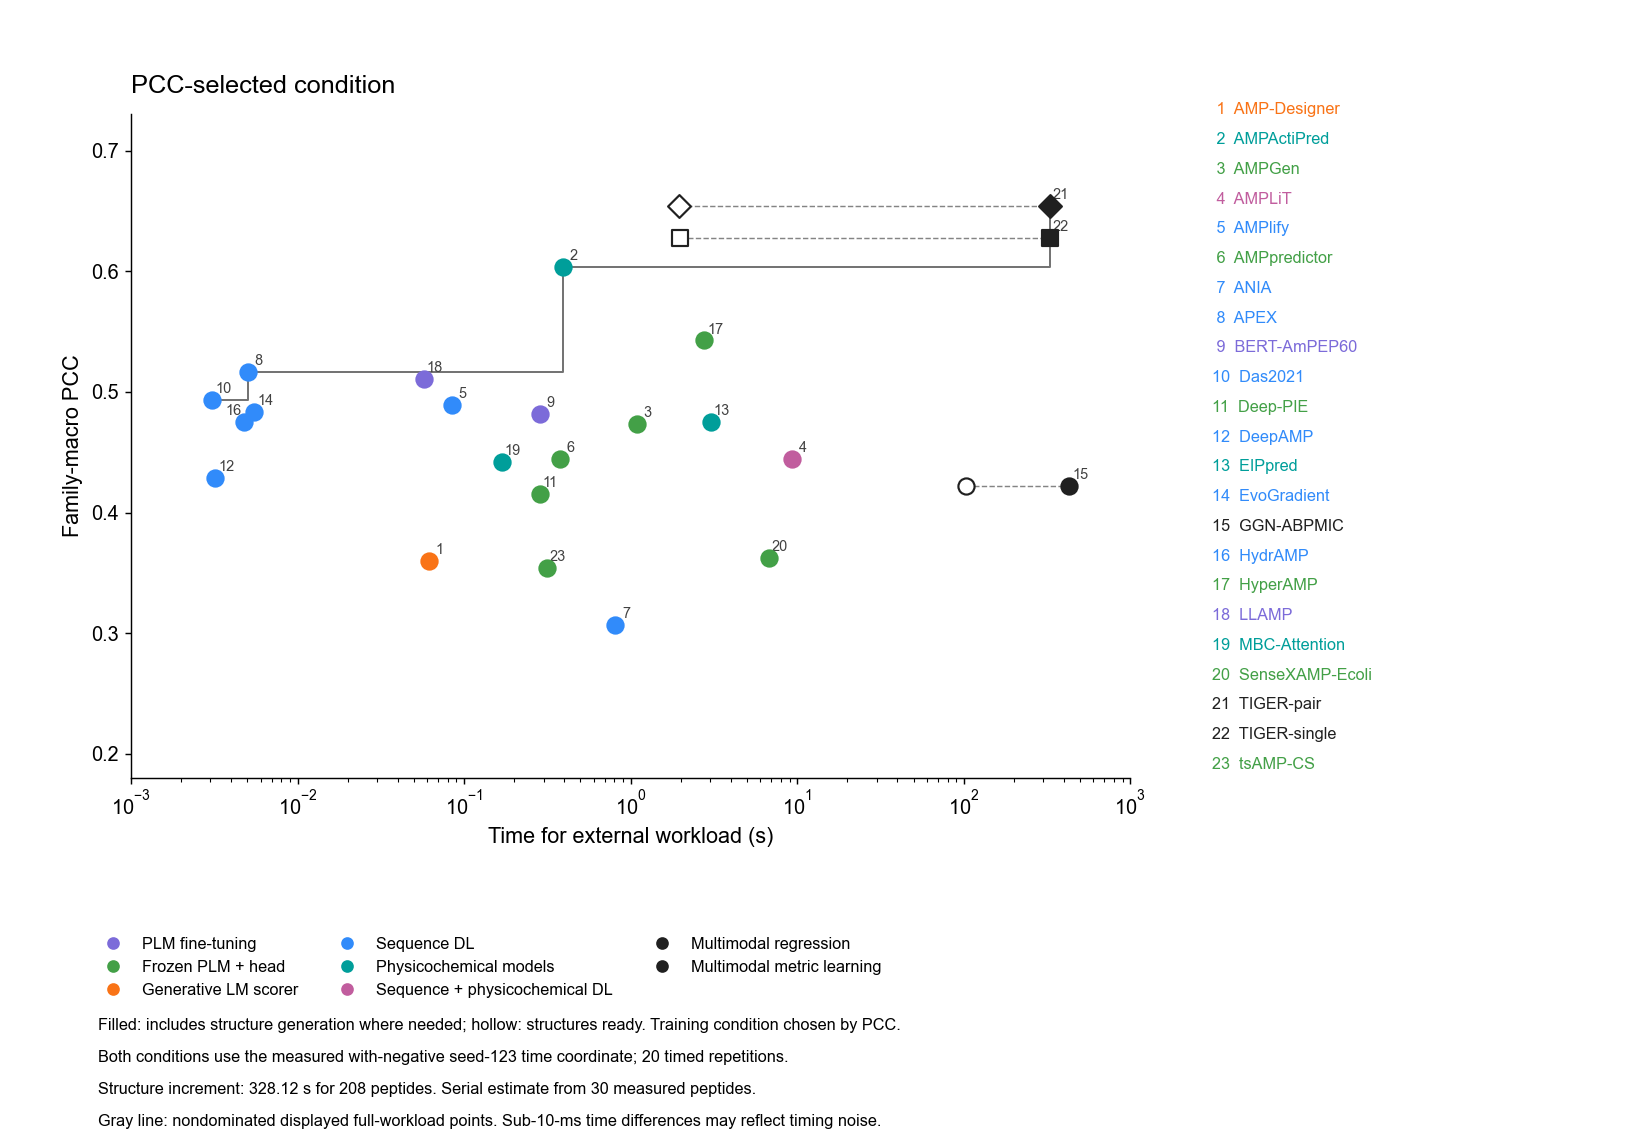

In [11]:
fig = plots.cost(OUT, metric='PCC', both=False, ensemble=False)
plots.export(fig, OUT / 'figures' / 'pareto_main_PCC')
show(fig)
plt.close(fig)


## Accuracy and cost — PCC, conditions

Both training conditions.  Timings use the with-negative seed-123 workload for both conditions. Structure generation adds a serial estimate of 328.12 s to structural pipelines. Dashed structural connectors and frontier segments are visual guides. The two condition points are connected and structures-ready points are omitted.

同时展示含／不含负样本，两点连线，取消结构已备点。两条件共用含负样本方案的计时；结构生成增加 328.12 s 串行估计。

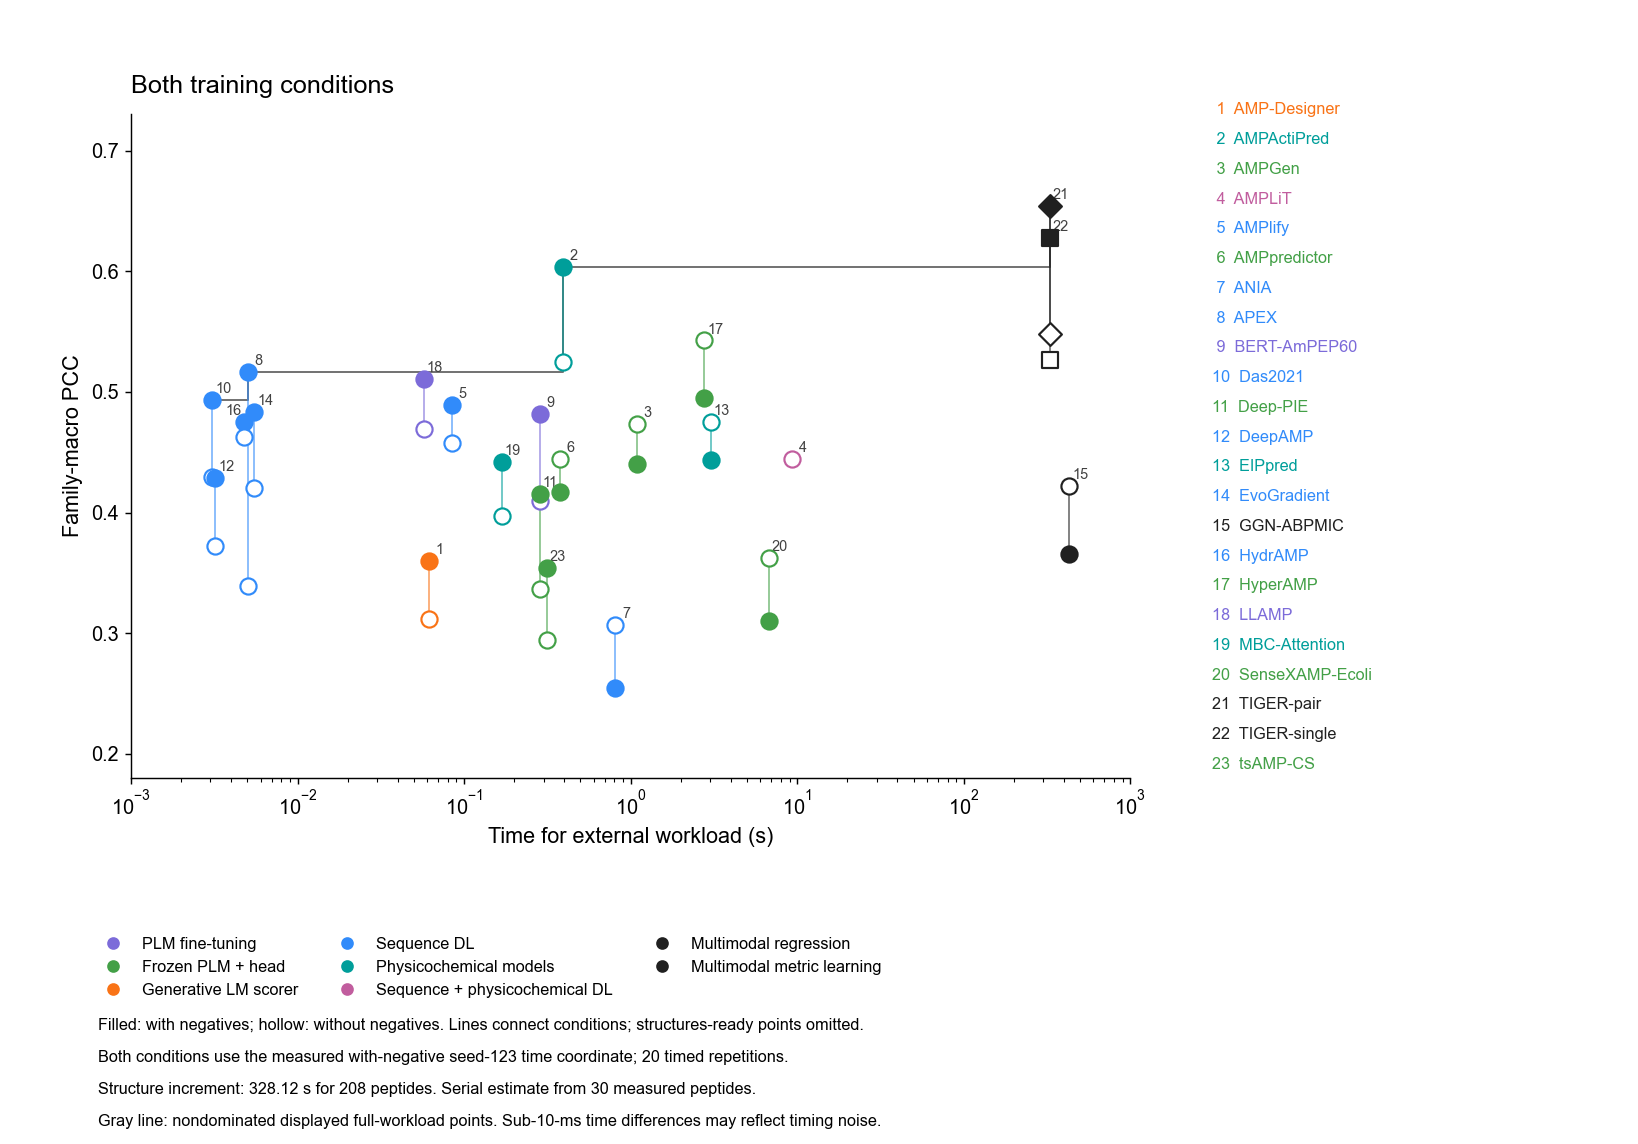

In [12]:
fig = plots.cost(OUT, metric='PCC', both=True, ensemble=False)
plots.export(fig, OUT / 'figures' / 'pareto_conditions_PCC')
show(fig)
plt.close(fig)


## Accuracy and cost — PCC, ensemble

One complete condition per backbone, selected by PCC.  Timings use the with-negative seed-123 workload for both conditions. Structure generation adds a serial estimate of 328.12 s to structural pipelines. Dashed structural connectors and frontier segments are visual guides. Hollow points indicate structures already available.

每个骨干按 PCC 选择一个完整方案，PCC 与 RSE 使用相同方案。空心点表示结构已备。两条件共用含负样本方案的计时；结构生成增加 328.12 s 串行估计。

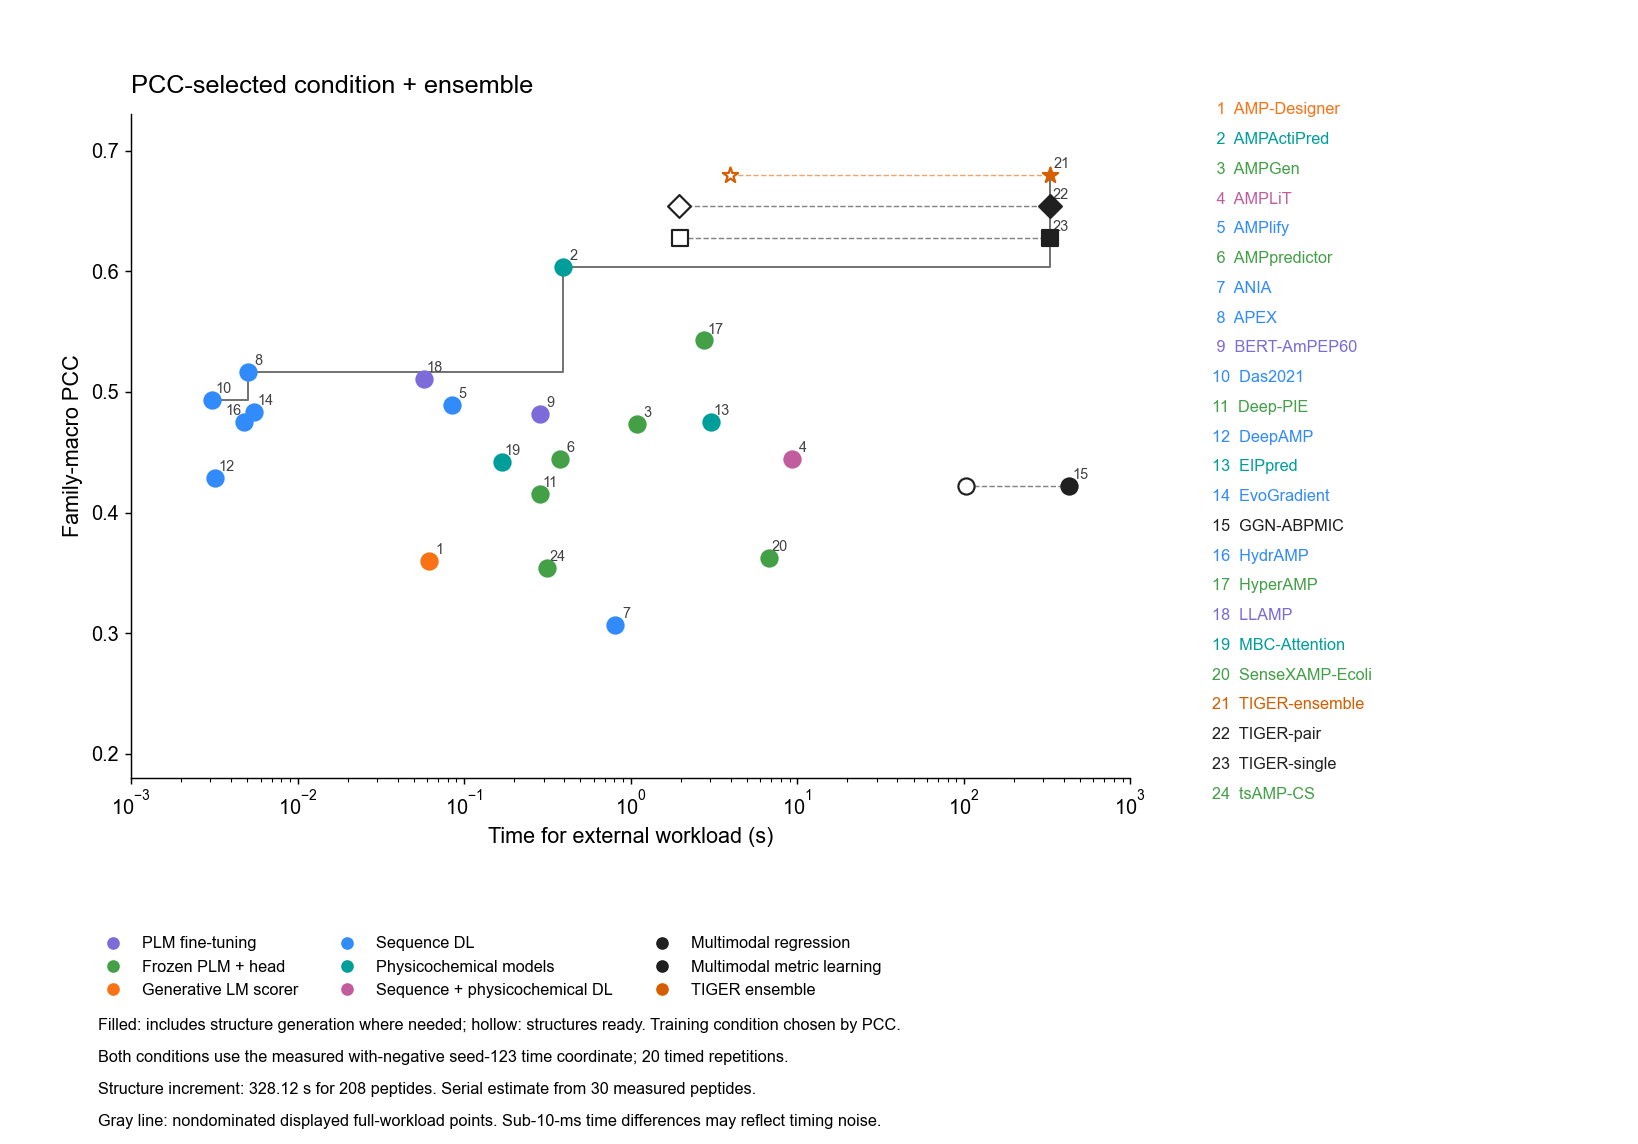

In [13]:
fig = plots.cost(OUT, metric='PCC', both=False, ensemble=True)
plots.export(fig, OUT / 'figures' / 'pareto_ensemble_PCC')
show(fig)
plt.close(fig)


## Accuracy and cost — RSE, main

One complete condition per backbone, selected by PCC. RSE uses the same PCC-selected condition; it is not independently optimized. Timings use the with-negative seed-123 workload for both conditions. Structure generation adds a serial estimate of 328.12 s to structural pipelines. Dashed structural connectors and frontier segments are visual guides. Hollow points indicate structures already available.

每个骨干按 PCC 选择一个完整方案，PCC 与 RSE 使用相同方案。空心点表示结构已备。两条件共用含负样本方案的计时；结构生成增加 328.12 s 串行估计。

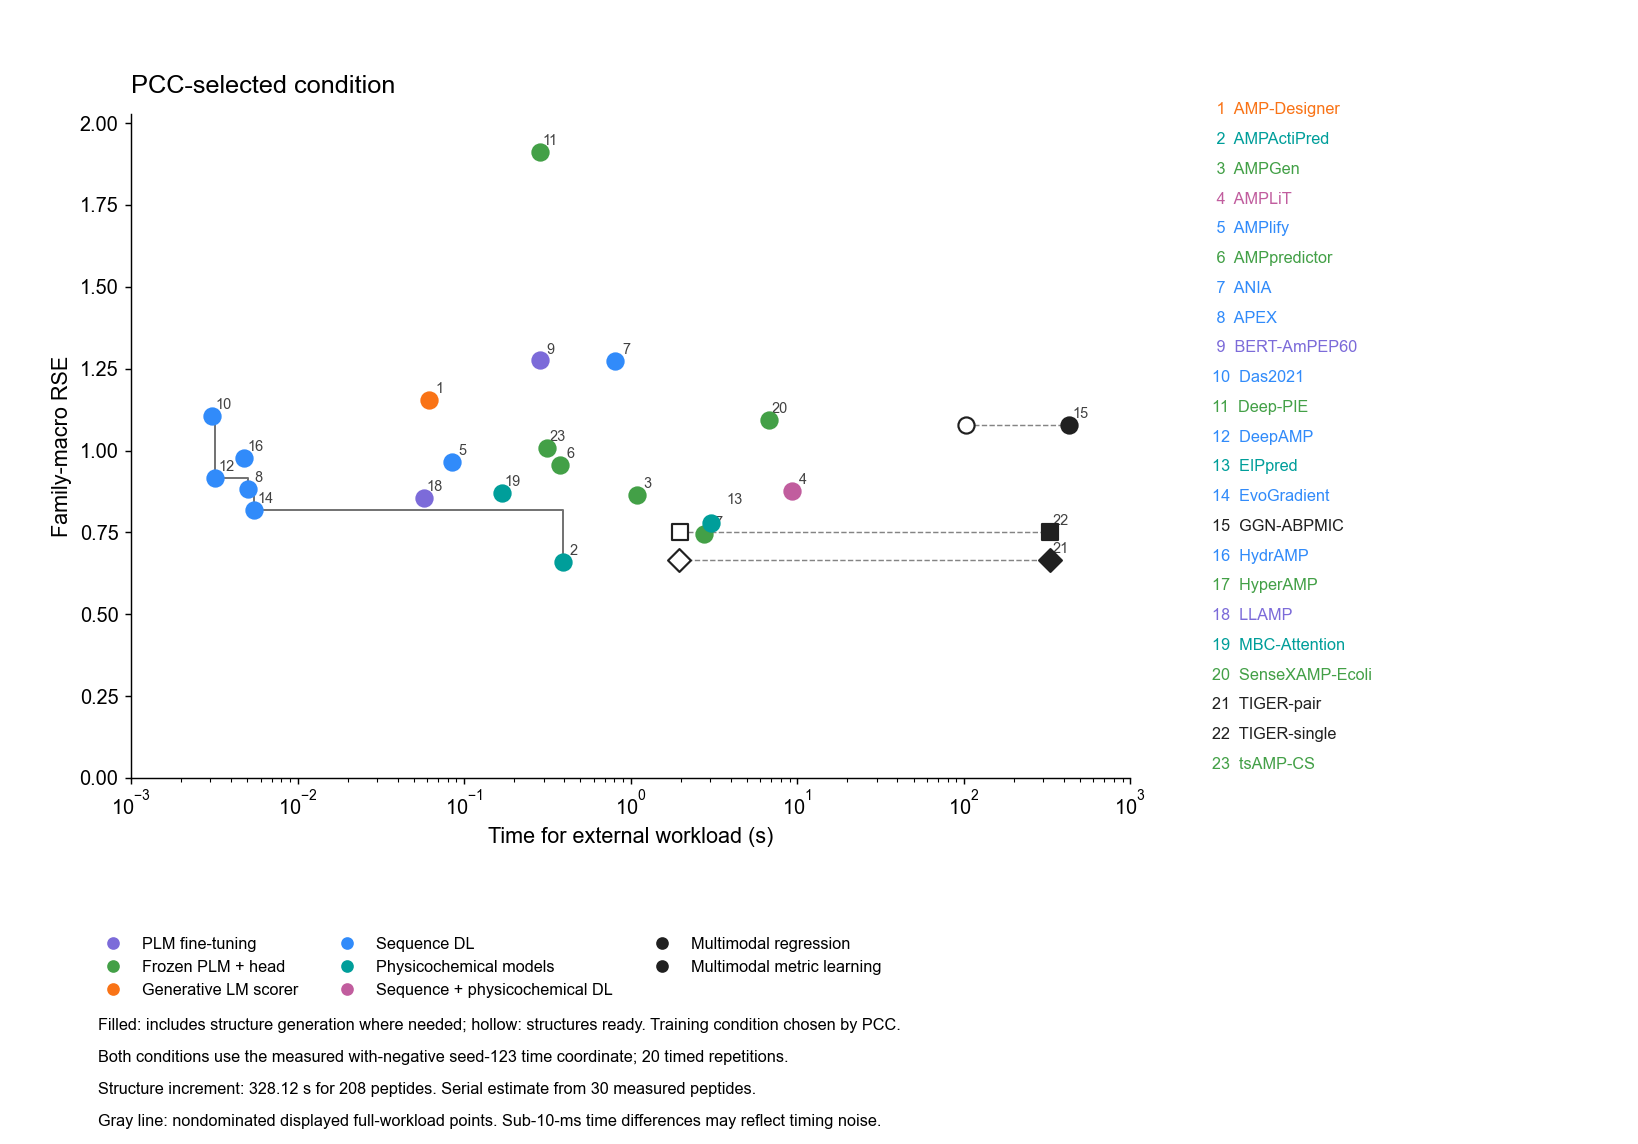

In [14]:
fig = plots.cost(OUT, metric='RSE', both=False, ensemble=False)
plots.export(fig, OUT / 'figures' / 'pareto_main_RSE')
show(fig)
plt.close(fig)


## Accuracy and cost — RSE, conditions

Both training conditions.  Timings use the with-negative seed-123 workload for both conditions. Structure generation adds a serial estimate of 328.12 s to structural pipelines. Dashed structural connectors and frontier segments are visual guides. The two condition points are connected and structures-ready points are omitted.

同时展示含／不含负样本，两点连线，取消结构已备点。两条件共用含负样本方案的计时；结构生成增加 328.12 s 串行估计。

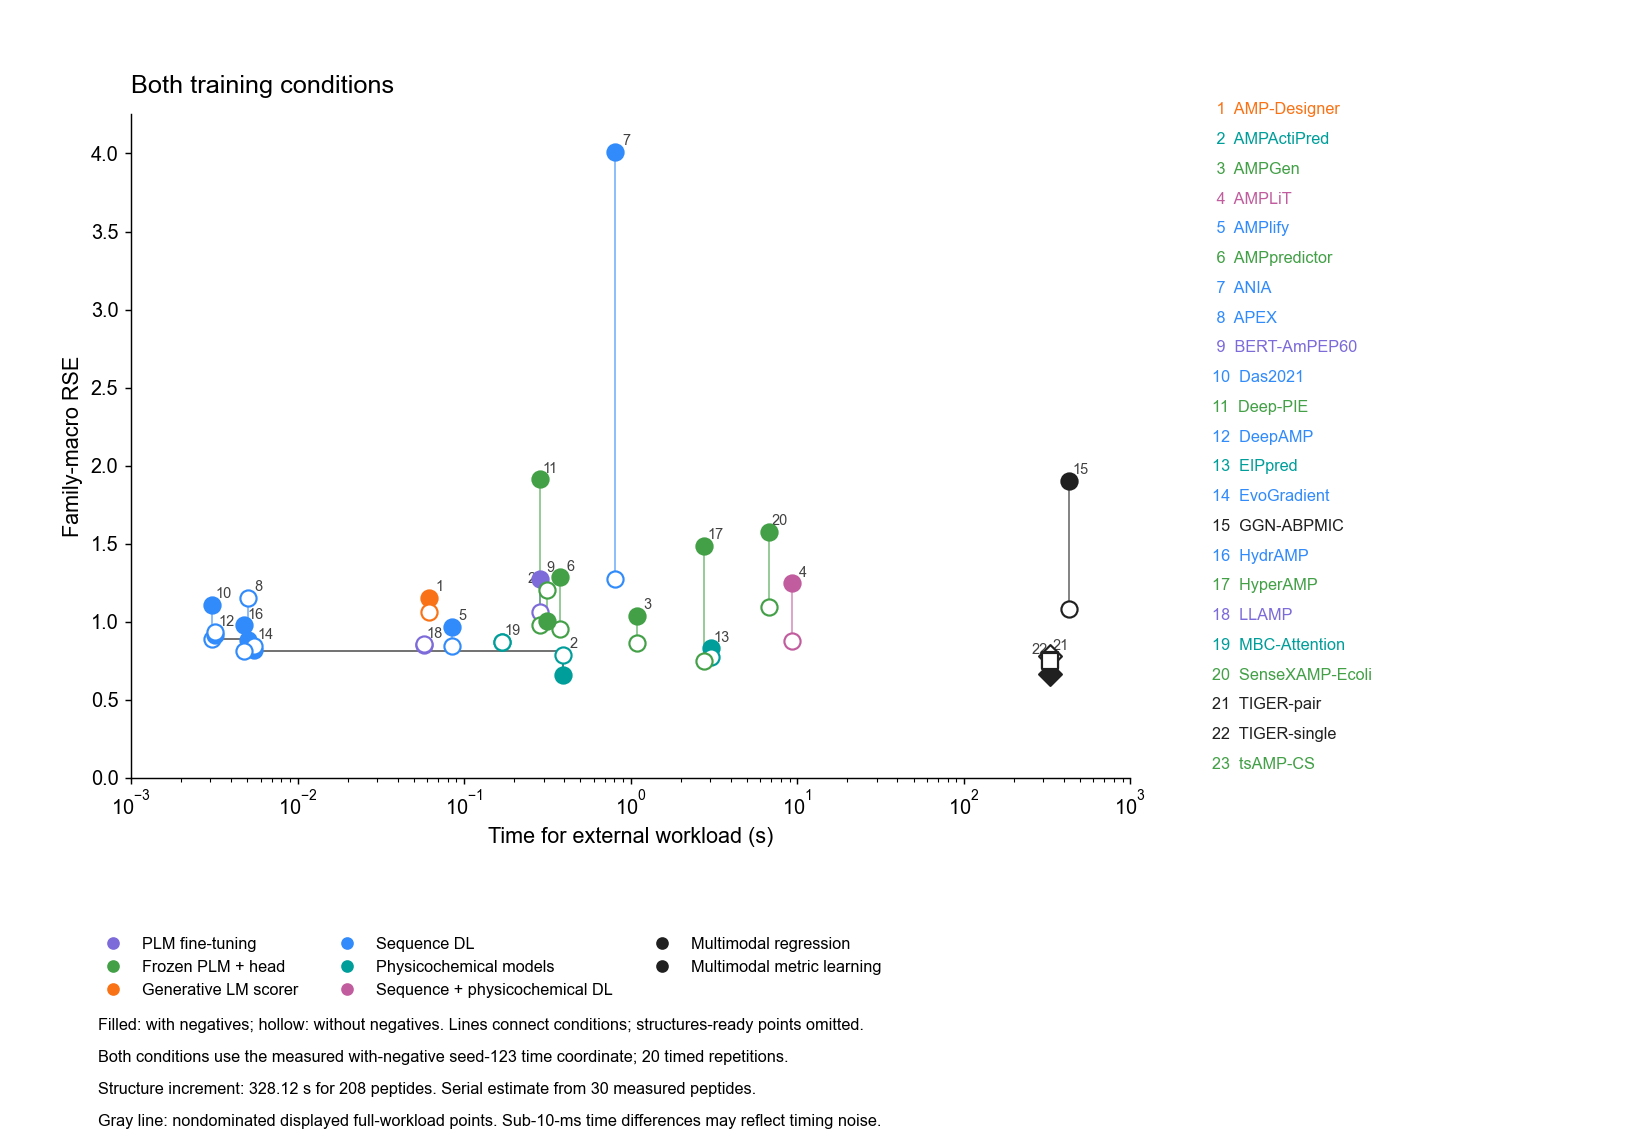

In [15]:
fig = plots.cost(OUT, metric='RSE', both=True, ensemble=False)
plots.export(fig, OUT / 'figures' / 'pareto_conditions_RSE')
show(fig)
plt.close(fig)


## Accuracy and cost — RSE, ensemble

One complete condition per backbone, selected by PCC. RSE uses the same PCC-selected condition; it is not independently optimized. Timings use the with-negative seed-123 workload for both conditions. Structure generation adds a serial estimate of 328.12 s to structural pipelines. Dashed structural connectors and frontier segments are visual guides. Hollow points indicate structures already available.

每个骨干按 PCC 选择一个完整方案，PCC 与 RSE 使用相同方案。空心点表示结构已备。两条件共用含负样本方案的计时；结构生成增加 328.12 s 串行估计。

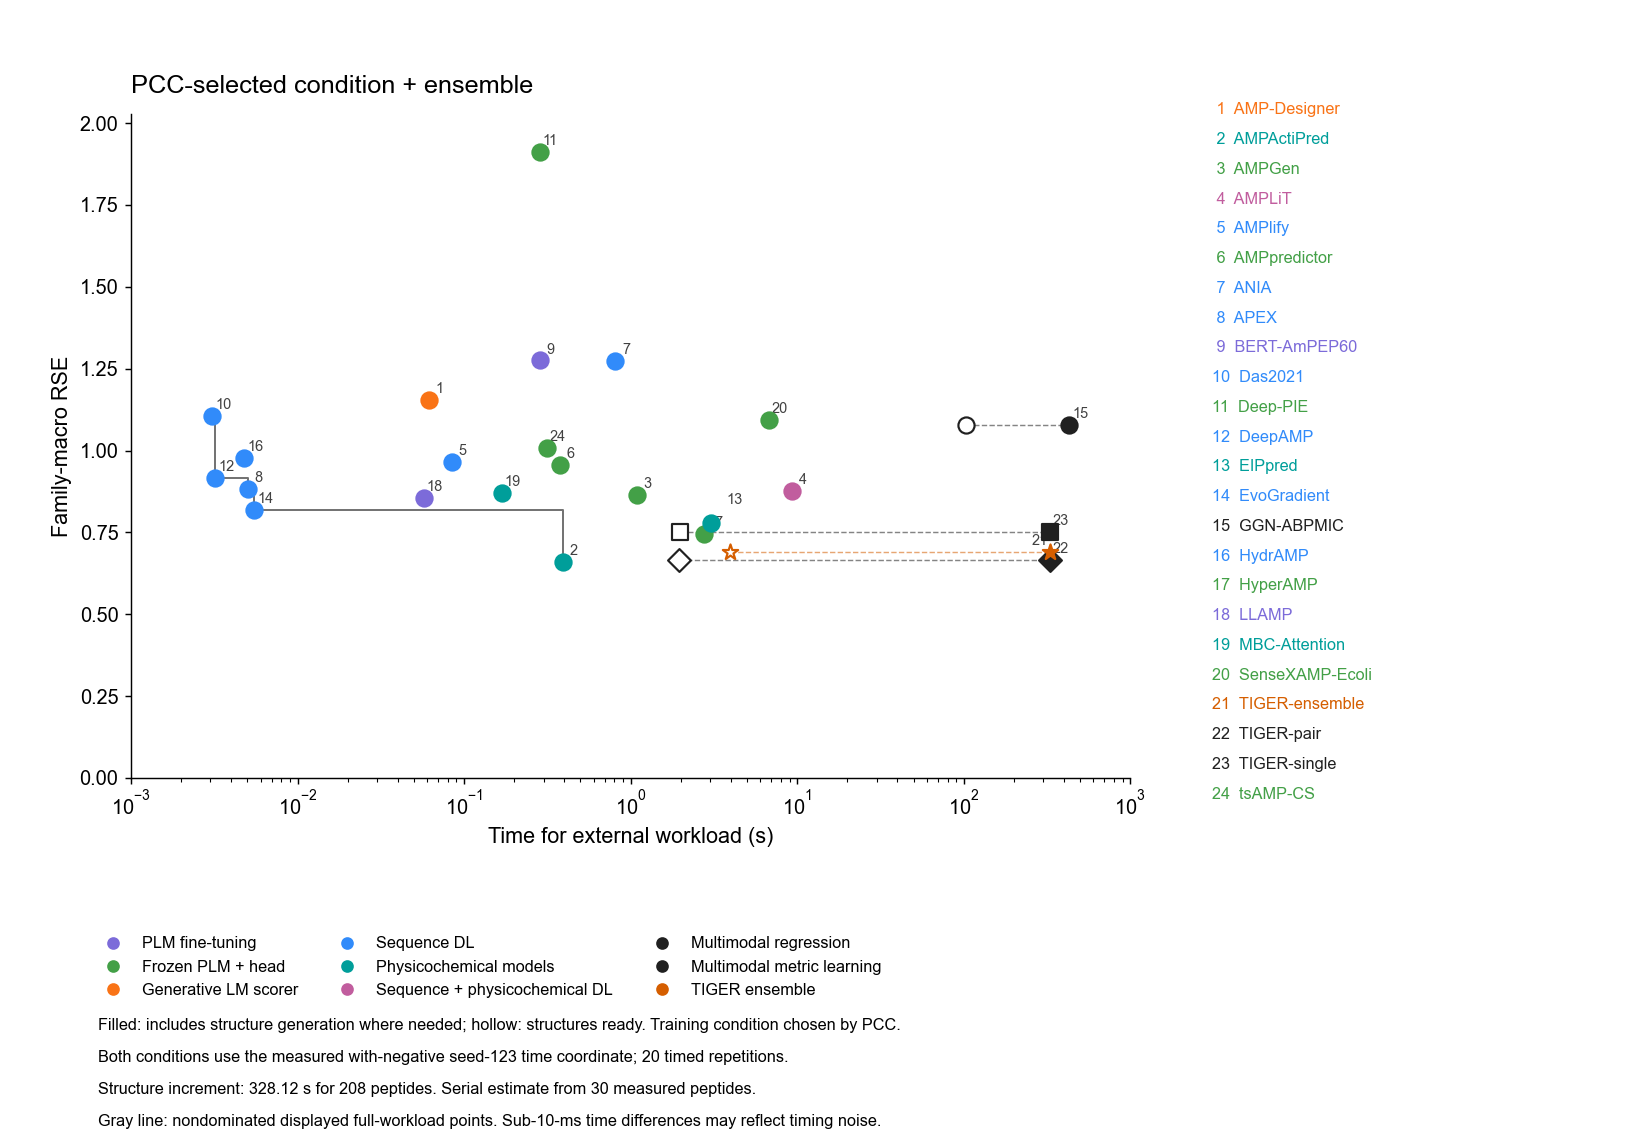

In [16]:
fig = plots.cost(OUT, metric='RSE', both=False, ensemble=True)
plots.export(fig, OUT / 'figures' / 'pareto_ensemble_RSE')
show(fig)
plt.close(fig)
